# Cutoff (shell) formulation at small $\Delta_0$

The model is fixed by the $T = 0$ gap $\Delta_0$; $V$ and $m_0$ follow from it (`cs.zero`).
Unknowns are only the excitations $n_\alpha$, $h_\beta = 1 - n_\beta$ in the shell $|\xi| < \Lambda$;
the rest of the band enters through 1D vacuum integrals over the DOS (`cs.lvac`, `cs.mvac`):

$$\int g\Big[\tfrac{1}{2E} - \tfrac{1}{2E_0}\Big] = \sum_{\rm shell} w \Big\langle \tfrac{1}{2E}\Big\rangle (n_\alpha + h_\beta),\qquad
m = -\int g\,\tfrac{\xi}{E} + \sum_{\rm shell} w \Big\langle\tfrac{\xi}{E}\Big\rangle (n_\alpha + h_\beta),\qquad
\sum_{\rm shell} w\,(n_\alpha - h_\beta) = 0 .$$

The code works in $t_a = 1$ eV, $a_0 = 1$; every printed or plotted energy is converted to Kelvin with `cm.kel`.

In [13]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

sys.path.insert(0, str(Path.cwd()))
import cut_model as cm
import cut_solve as cs

kel = cm.kel
band = dict(gap=4.0, ta=1.0, tb=-1.0)
set1_list = plt.get_cmap("Set1").colors
W = 3.47412


def style(ax, x=None):
    ax.grid(alpha=0.3)
    ax.tick_params(which="both", direction="in")
    if x is not None:
        ax.set_xlim(np.min(x), np.max(x))


# apply_plt_style()
# pt = Plotter(show=True, close=False)
plt.rcParams.update(
    {
        "text.usetex": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Calibri"],
        "font.size": 8,
        "mathtext.fontset": "cm",
    }
)
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)

FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

## 1. Scales for a given $\Delta_0$

`cs.zero` solves the $T = 0$ equations for $V$ and $m_0$ at fixed $\Delta_0$; `cs.tc` solves the subtracted
Thouless equation. Both are 1D integrals in $u = \operatorname{asinh}(\xi / a)$, with no k grid and no $e^{+E/T}$.

In [15]:
d0s = [0.1, 0.03, 0.015]
cz = {d0: cs.zero(**band, d0=d0) for d0 in d0s}
tcs = {d0: cs.tc(c) for d0, c in cz.items()}
print("  d0 [K]     V [K]      m0        s*      Tc [K]     d0 / Tc")
for d0, c in cz.items():
    p = c.p
    print(f"{kel(d0):9.2f}  {kel(p.v):9.1f}  {c.m0:+.6f}  {cs.xc(p, c.m0) / (p.ta - p.tb):.4f}  "
          f"{kel(tcs[d0]):9.3f}  {d0 / tcs[d0]:.4f}")

  d0 [K]     V [K]      m0        s*      Tc [K]     d0 / Tc
  1160.45    28129.1  -0.829794  1.5028    656.760  1.7669
   348.14    20920.2  -0.772762  1.3483    197.353  1.7640
   174.07    18329.6  -0.753132  1.2974     98.683  1.7639


In [16]:
# Delta_0 and Tc against V (V follows from d0, no root search in V)
dd = np.geomspace(2e-3, 1.e-1, 20)
zz = [cs.zero(**band, d0=x, branch="bec") for x in dd]
vv = ([z.p.v for z in zz]) 
tt = kel([cs.tc(z) for z in zz])


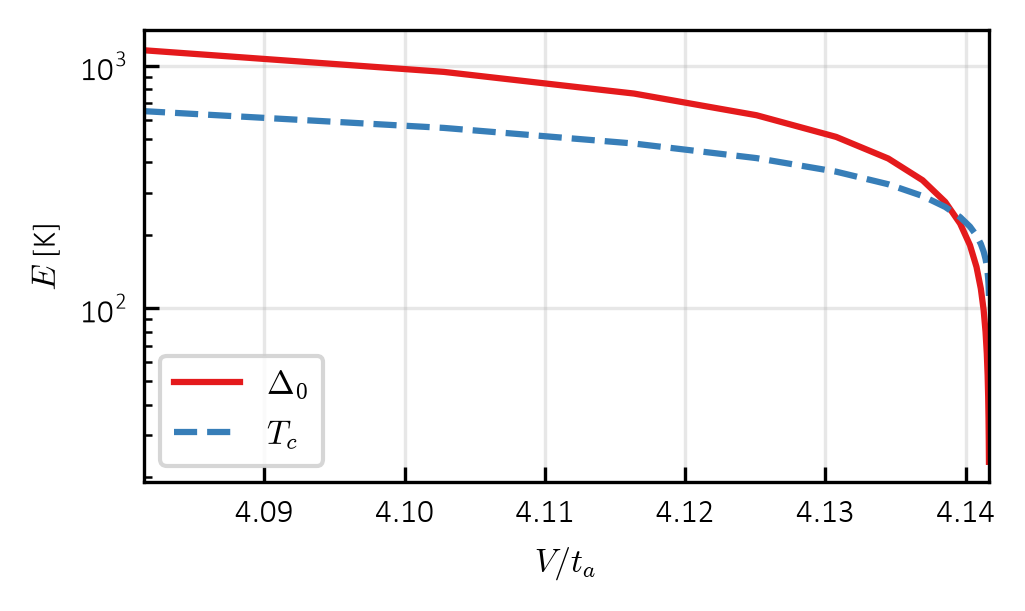

In [17]:

fig, ax = plt.subplots(figsize=(W, 0.6 * W))
ax.semilogy(vv, kel(dd), color=set1_list[0], label=r"$\Delta_0$")
ax.semilogy(vv, tt, "--", color=set1_list[1], label=r"$T_c$")
ax.set_xlabel(r"$V/t_a$")
ax.set_ylabel(r"$E$ [K]")
ax.legend()
style(ax, vv)
plt.tight_layout()
# plt.savefig(FIG_PATH + "BCS_d0_equi+librium_VTc.pdf", bbox_inches="tight")
plt.show()

## 2. Equilibrium $\Delta(T)$: grid free and on the shell grid

`cs.faces(lam, a, n)`: $n$ (odd) cells in $\xi$, sinh spaced, width $a\,du$ at the ring and $|\xi|\,du$ further out.
Here $\Lambda = 40 T_c$ and $a = 0.1 \Delta_0$. The cells are fixed in $\xi$ and move with $m$ in $s$ (`cs.cells`).

In [18]:
tr = np.linspace(0.05, 0.98, 32)
for i, d0 in enumerate([0.1, 0.015]):
    c, tc = cz[d0], tcs[d0]
    dq, z = [], (d0, c.m0)
    for t in tr * tc:                                  # continuation in T
        z = cs.thermal(c, t, *z)[:2]
        dq.append(z)
    dq = np.array(dq)
    xf = cs.faces(c, 40 * tc, 0.1 * d0, 401)
    ds = np.array([cs.thermal_shell(c, xf, t, *z)[0] for t, z in zip(tr[::3] * tc, dq[::3])])
    print(f"d0 = {kel(d0):.2f} K, Tc = {kel(tc):.3f} K: max |d_shell - d_quad| = "
          f"{np.max(np.abs(kel(ds - dq[::3, 0]))):.2e} K (n = 401)")

    fig, ax = plt.subplots(figsize=(W, 0.6 * W))
    ax.plot(kel(tr * tc), kel(dq[:, 0]), color=set1_list[0], label="quad")
    ax.plot(kel(tr[::3] * tc), kel(ds), "o", ms=3, mfc="none", color=set1_list[1], label="shell")
    ax.set_xlabel(r"$T\,[\mathrm{K}]$")
    ax.set_ylabel(r"$\Delta\,[\mathrm{K}]$")
    ax.legend()
    style(ax, kel(tr * tc))
    plt.tight_layout()
    plt.show()

ValueError: the shell leaves the band, reduce lam

In [ ]:
# shell discretization error at 0.95 Tc against the number of cells (second order)
for d0 in [0.1, 0.015]:
    c, tc = cz[d0], tcs[d0]
    d, m, _ = cs.thermal(c, 0.95 * tc)
    er = [kel(cs.thermal_shell(c, cs.faces(c, 40 * tc, 0.1 * d0, n), 0.95 * tc, d, m)[0] - d)
          for n in (201, 401, 801)]
    print(f"d0 = {kel(d0):.2f} K, d(0.95 Tc) = {kel(d):.4f} K: d_shell - d_quad = "
          + ", ".join(f"{e:+.2e} K" for e in er) + "  (n = 201, 401, 801)")

d0 = 1160.45 K, d(0.95 Tc) = 441.3536 K: d_shell - d_quad = +1.05e+00 K, +2.64e-01 K, +6.63e-02 K  (n = 201, 401, 801)
d0 = 174.07 K, d(0.95 Tc) = 66.2006 K: d_shell - d_quad = +1.58e-01 K, +3.97e-02 K, +9.95e-03 K  (n = 201, 401, 801)


## 3. Moving ring

The ring moves by $\delta\xi = \tfrac{h}{2}(m - m_0)$, i.e. $\delta s^* = -h (m - m_0) / 2(t_a - t_b)$.
The cells move with it, so only the weights change.

In [ ]:
for d0 in [0.1, 0.015]:
    c, tc = cz[d0], tcs[d0]
    xf = cs.faces(c, 40 * tc, 0.1 * d0, 401)
    _, m, _ = cs.thermal(c, 0.95 * tc)
    dx = 0.5 * c.p.h * (m - c.m0)
    print(f"d0 = {kel(d0):.2f} K: ring shift at 0.95 Tc {kel(dx):+.3f} K, "
          f"central cell {kel(np.min(np.diff(xf))):.3f} K, shell edge {kel(xf[-1]):.1f} K")

d0 = 1160.45 K: ring shift at 0.95 Tc -11.280 K, central cell 3.541 K, shell edge 26315.7 K
d0 = 174.07 K: ring shift at 0.95 Tc -0.285 K, central cell 0.531 K, shell edge 3947.4 K


## 4. NESS at $\Delta_0 = 0.015$ ($T_c \approx 99$ K)

Photon at $T_1$ (vertical, $\omega_0 = 0$, $\gamma = 0.1\Delta_0$), phonon at $T_2$ (Fokker-Planck).
The phonons conserve the band numbers and are about $10^{16}$ times faster than the photons on the fine cells,
so the $\mu$ rows cannot fix the pair number $N_\alpha + H_\beta$. `cs.resid` therefore adds the row
`cs.jlog` $= 0$ (summed interband photon balance), which every steady state satisfies.

In [26]:
# Delta against T1 at T2 = 0.2 Tc (n = 201 cells), BEC branch
d0 = 0.015
c = cs.zero(**band, d0=d0, branch="bec")      # "bcs" for the smaller V
tc = cs.tc(c)
t2 = 0.2 * tc
pc = dict(amp=1.0, dip=2.0, c=200.0, w0=0.0, gam=0.1 * d0)
qc = dict(amp=1.0, ta_prime=-1.0, tb_prime=1.0, line="fp", gam=0.1 * d0)

t1r = np.linspace(0.3, 1.5, 9)
xf = cs.faces(c, 25 * tc * t1r.max(), 0.1 * min(d0, t2), 201)   # anchored at the band edge for BEC
t1, t2 = 0.6 * tc, 0.2 * tc
xf = cs.faces(c, 40 * tc, 0.1 * d0, 401)
print(f"T1 = {kel(t1):.3f} K, T2 = {kel(t2):.3f} K, shell |xi| < {kel(xf[-1]):.1f} K")

d, m, mu = cs.thermal_shell(c, xf, t2, d0, c.m0)
r, _ = cs.resid(np.r_[mu, d, m], c, xf, pc, qc, t2, t2)
print(f"T1 = T2: max residual of the shell equilibrium {np.max(np.abs(r)):.1e}")

s = cs.ness(c, xf, pc, qc, t1, t2)
teff = brentq(lambda t: cs.thermal(c, t, s.d, s.m)[0] - s.d, 0.05 * tc, 0.99 * tc)
print(f"NESS: d = {kel(s.d):.4f} K (d0 = {kel(d0):.4f} K), m = {s.m:.8f}, err {s.err:.1e}, "
      f"T_eff = {kel(teff):.3f} K")

T1 = 127.839 K, T2 = 42.613 K, shell |xi| < 8522.6 K
T1 = T2: max residual of the shell equilibrium 2.8e-14
NESS: d = 171.4808 K (d0 = 174.0678 K), m = -0.99987123, err 1.7e-13, T_eff = 120.432 K


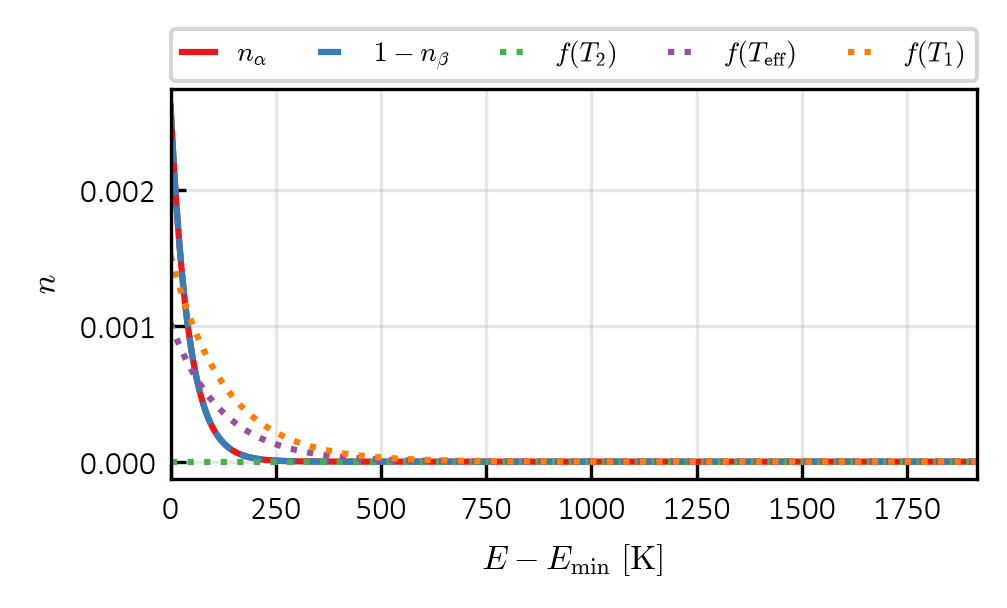

In [27]:
gr = cs.cells(c, xf, s.m)
x = 0.5 * (gr.xf[1:] + gr.xf[:-1])               # true xi of the cell centres
e, ns = np.hypot(x, s.d), len(x)
n, nb = cs.occ(s.mu)
k = e - e.min() < 15 * t1                        # plotted part of the shell
de = kel(e[k] - e.min())
ts = [(t2, r"T_2"), (teff, r"T_{\rm eff}"), (t1, r"T_1")]

fig, ax = plt.subplots(figsize=(W, 0.6 * W))
ax.plot(de, n[:ns][k], color=set1_list[0], label=r"$n_{\alpha}$")
ax.plot(de, nb[ns:][k], "--", color=set1_list[1], label=r"$1 - n_{\beta}$")
for i, (t, lb) in enumerate(ts):
    ax.plot(de, cm.fd(e[k], t), ":", color=set1_list[i + 2], label=rf"$f({lb})$")
ax.set_xlabel(r"$E - E_{\min}\,[\mathrm{K}]$")
ax.set_ylabel(r"$n$")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=5,
          handlelength=1.2, columnspacing=0.6, fontsize="small")
style(ax, de)
plt.tight_layout()
plt.show()

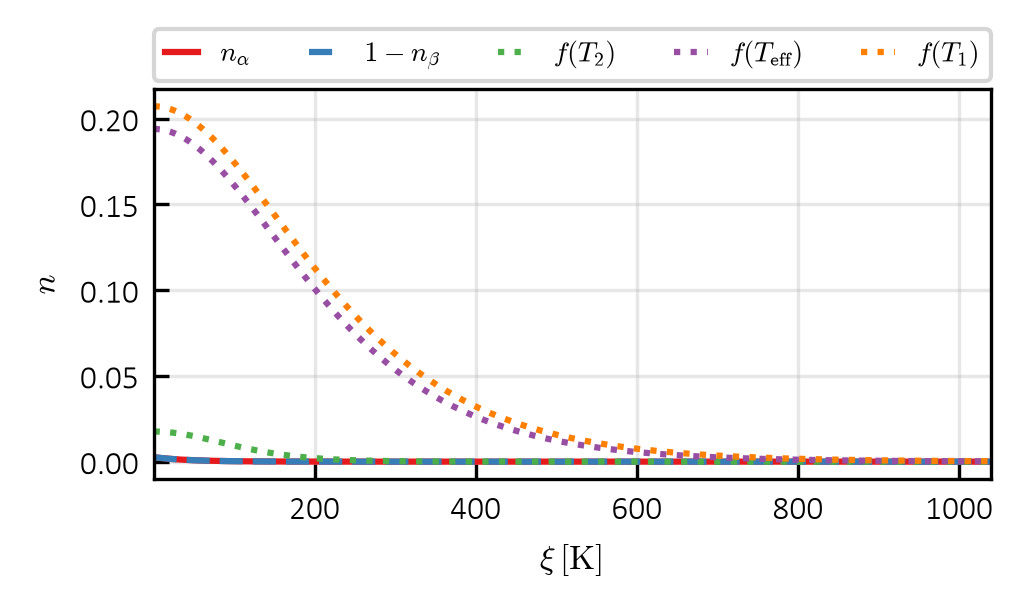

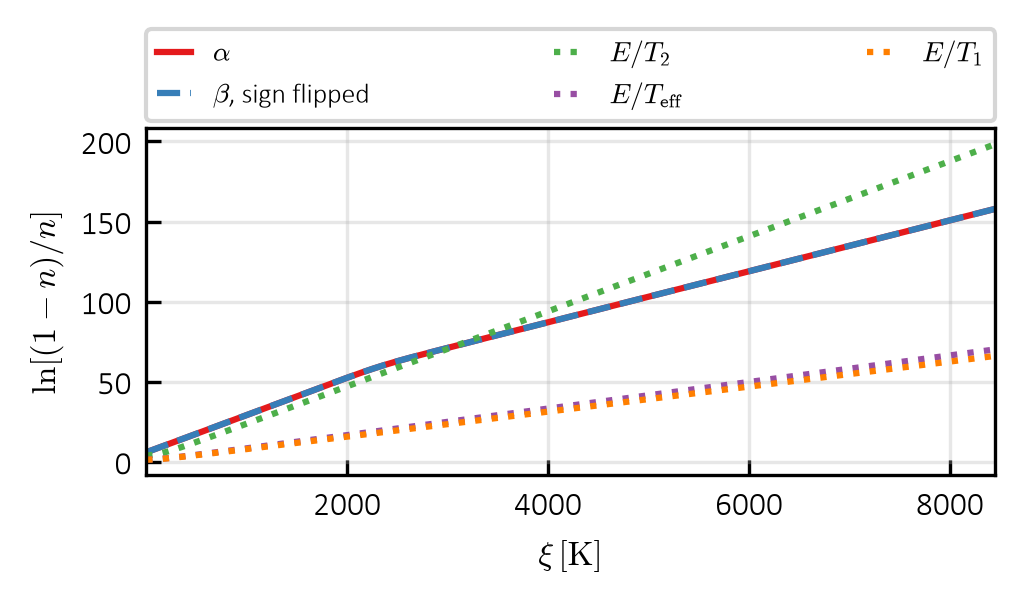

In [28]:
x = 0.5 * (xf[1:] + xf[:-1])                      # cell centres in xi
e, ns = np.hypot(x, s.d), len(x)
n, nb = cs.occ(s.mu)
k = np.abs(x) < 6 * d0                            # plotted part of the shell
ts = [(t2, r"T_2"), (teff, r"T_{\rm eff}"), (t1, r"T_1")]

fig, ax = plt.subplots(figsize=(W, 0.6 * W))
ax.plot(kel(x[k]), n[:ns][k], color=set1_list[0], label=r"$n_{\alpha}$")
ax.plot(kel(x[k]), nb[ns:][k], "--", color=set1_list[1], label=r"$1 - n_{\beta}$")
for i, (t, lb) in enumerate(ts):
    ax.plot(kel(x[k]), cm.fd(e[k], t), ":", color=set1_list[i + 2], label=rf"$f({lb})$")
# ax.set_ylim(1e-12, 1)
ax.set_xlabel(r"$\xi\,[\mathrm{K}]$")
ax.set_ylabel(r"$n$")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=5,
          handlelength=1.2, columnspacing=0.6, fontsize="small")
style(ax, kel(x[k]))
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(W, 0.6 * W))
ax.plot(kel(x), s.mu[:ns], color=set1_list[0], label=r"$\alpha$")
ax.plot(kel(x), -s.mu[ns:], "--", color=set1_list[1], label=r"$\beta$, sign flipped")
for i, (t, lb) in enumerate(ts):
    ax.plot(kel(x), e / t, ":", color=set1_list[i + 2], label=rf"$E / {lb}$")
ax.set_xlabel(r"$\xi\,[\mathrm{K}]$")
ax.set_ylabel(r"$\ln[(1 - n) / n]$")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=3,
          handlelength=1.2, columnspacing=0.6, fontsize="small")
style(ax, kel(x))
plt.tight_layout()
plt.show()

In [29]:
# cb = {br: cs.zero(**band, d0=d0, branch=br) for br in ("bcs", "bec")}
# tcb = {br: cs.tc(c) for br, c in cb.items()}
# for br, c in cb.items():
#     p = c.p
#     gx = 0.0 if c.edge is None else abs(cs.xc(p, c.m0) - (p.ta - p.tb) * c.edge)
#     print(f"{br}: V = {kel(p.v):9.2f} K, 1 + m0 = {1 + c.m0:.3e}, edge {c.edge}, "
#           f"min |xi| = {kel(gx):8.1f} K, Tc = {kel(tcb[br]):8.3f} K, Tc / d0 = {tcb[br] / d0:.3f}")

# # BEC NESS, photon at T1 = 0.9 Tc, phonon (Fokker-Planck) at T2 = 0.2 Tc
# c, tc = cb["bec"], tcb["bec"]
# t1, t2 = 0.9 * tc, 0.2 * tc
# pc = dict(amp=1.0, dip=2.0, c=200.0, w0=0.0, gam=0.1 * d0)
# qc = dict(amp=1.0, ta_prime=-1.0, tb_prime=1.0, line="fp", gam=0.1 * d0)
# xf = cs.faces(c, 40 * tc, 0.1 * min(d0, t2), 401)

# d, m, mu = cs.thermal_shell(c, xf, t2, d0, c.m0)
# r, _ = cs.resid(np.r_[mu, d, m], c, xf, pc, qc, t2, t2)
# print(f"T1 = T2: max residual of the shell equilibrium {np.max(np.abs(r)):.1e}")
# s = cs.ness(c, xf, pc, qc, t1, t2)
# teff = brentq(lambda t: cs.thermal(c, t, s.d, s.m)[0] - s.d, 0.05 * tc, 0.99 * tc)
# print(f"T1 = {kel(t1):.2f} K, T2 = {kel(t2):.2f} K: d = {kel(s.d):.4f} K (d0 = {kel(d0):.2f} K), "
#       f"1 + m = {1 + s.m:.4e}, err {s.err:.1e}, T_eff = {kel(teff):.2f} K")

# gr = cs.cells(c, xf, s.m)
# x = 0.5 * (gr.xf[1:] + gr.xf[:-1])
# e, ns = np.hypot(x, s.d), len(x)
# n, nb = cs.occ(s.mu)
# k = e - e.min() < 15 * t1                         # plotted part of the shell
# de = kel(e[k] - e.min())
# fig, ax = plt.subplots(figsize=(W, 0.6 * W))
# ax.semilogy(de, n[:ns][k], color=set1_list[0], label=r"$n_{\alpha}$")
# ax.semilogy(de, nb[ns:][k], "--", color=set1_list[1], label=r"$1 - n_{\beta}$")
# for i, (t, lb) in enumerate([(t2, r"T_2"), (teff, r"T_{\rm eff}"), (t1, r"T_1")]):
#     ax.semilogy(de, cm.fd(e[k], t), ":", color=set1_list[i + 2], label=rf"$f({lb})$")
# ax.set_xlabel(r"$E - E_{\min}\,[\mathrm{K}]$")
# ax.set_ylabel(r"$n$")
# ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=5,
#           handlelength=1.2, columnspacing=0.6, fontsize="small")
# style(ax, de)
# plt.tight_layout()
# plt.show()

Total points in ring region: 1884
0.1884
equiv grid 43


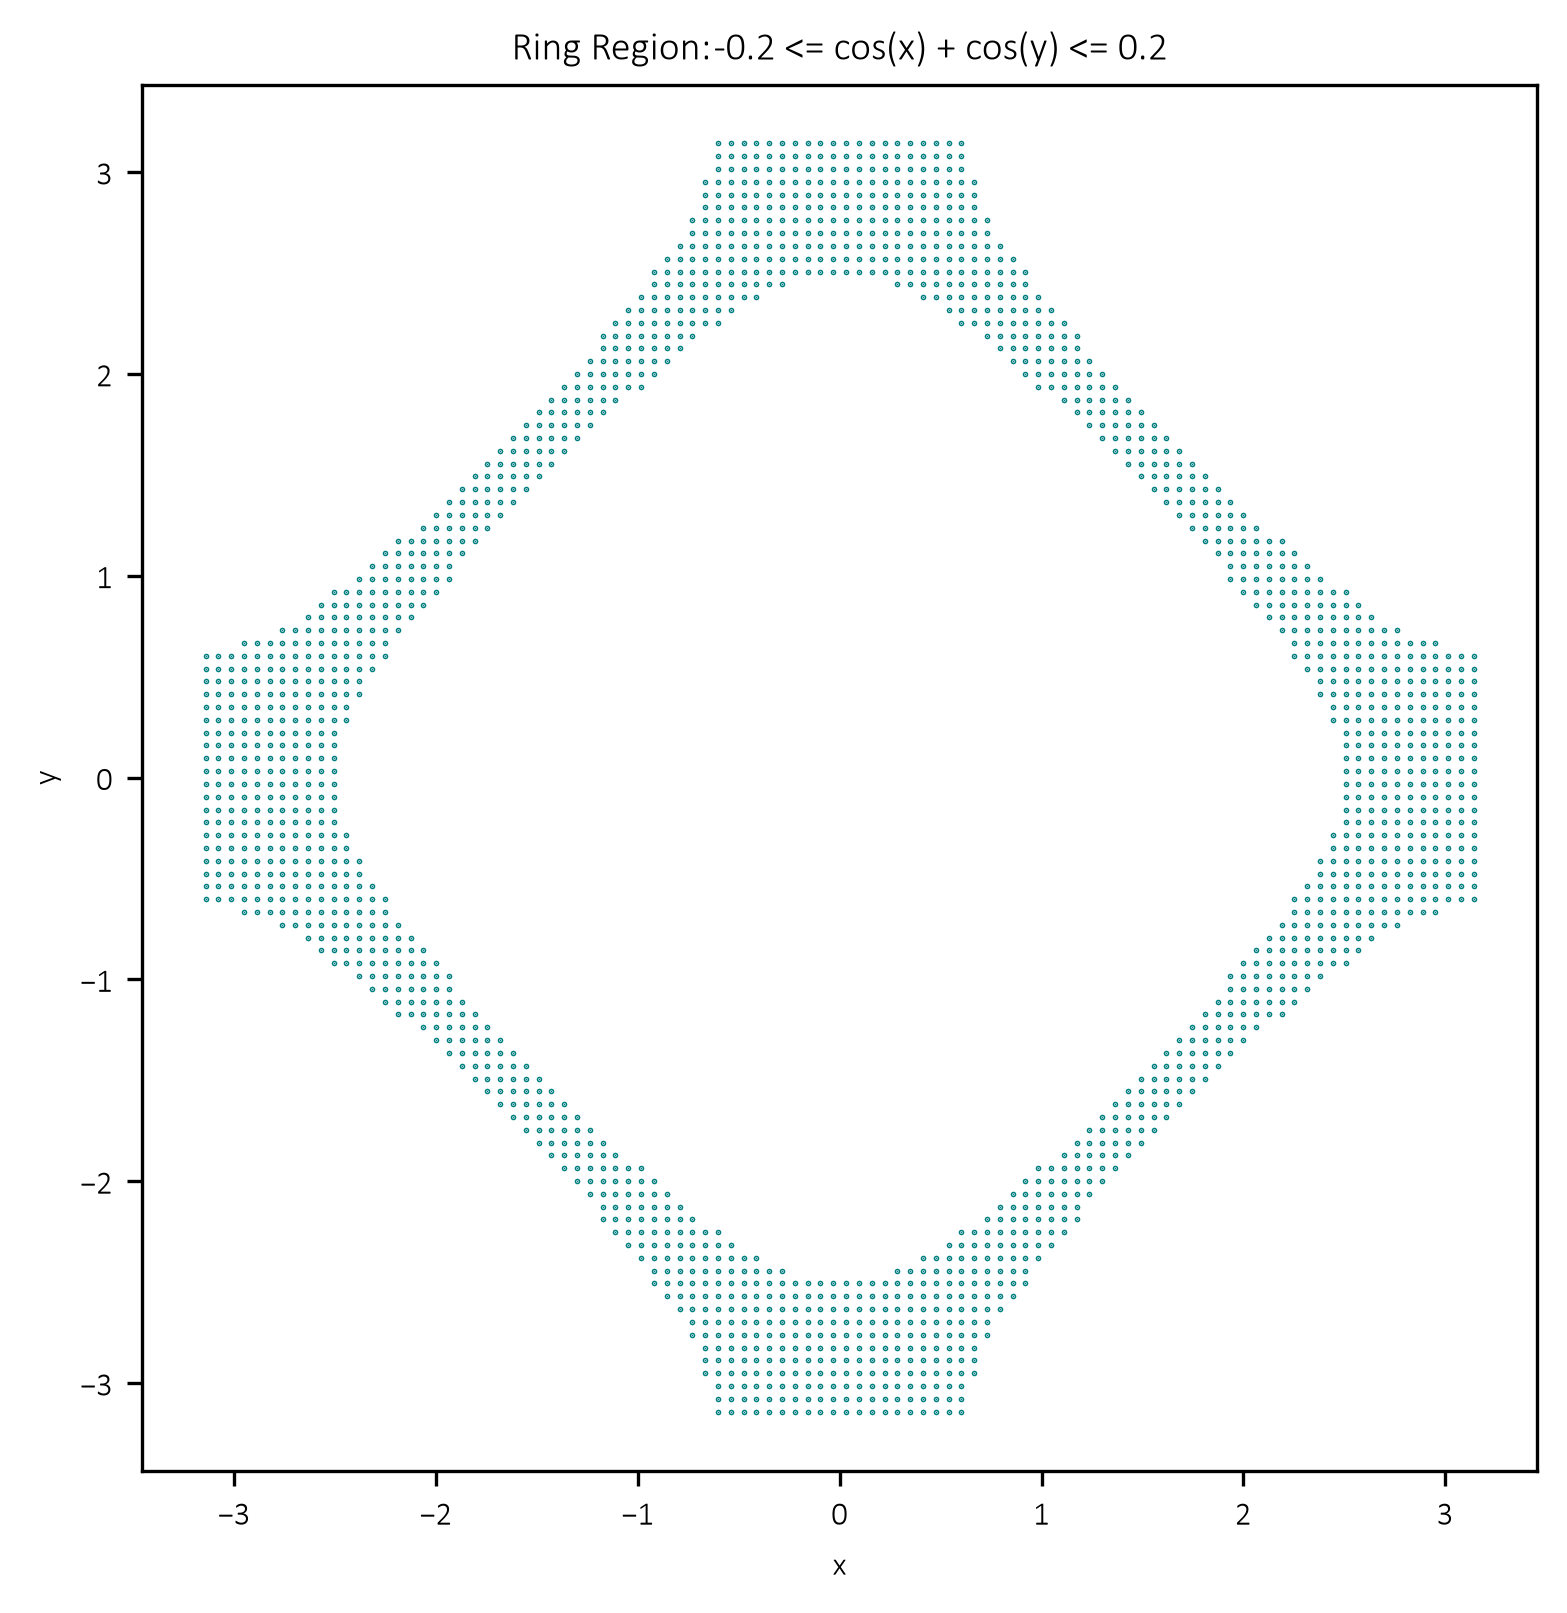

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Define the coordinate grid
resolution = 100
x = np.linspace(-np.pi, np.pi, resolution)
y = np.linspace(-np.pi, np.pi, resolution)
X, Y = np.meshgrid(x, y)

# 2. Compute the contour function s = cos(x) + cos(y)
S = np.cos(X) + np.cos(Y)

# 3. Define the ring bounds
s_min = -0.2
s_max = 0.2

# 4. Create a boolean mask for the band/ring region
ring_mask = (S >= s_min) & (S <= s_max)

# Extract the Cartesian points inside the ring
ring_x = X[ring_mask]
ring_y = Y[ring_mask]
ring_points = np.column_stack((ring_x, ring_y))

print(f"Total points in ring region: {ring_points.shape[0]}")
print(ring_points.shape[0]/resolution**2)
print("equiv grid", int(np.sqrt(ring_points.shape[0])))

# Optional: Visualize the result
plt.figure(figsize=(6, 6))
plt.scatter(
    ring_points[:, 0], ring_points[:, 1], s=0.5, color="teal", marker="."
)
plt.title(f"Ring Region: {s_min} <= cos(x) + cos(y) <= {s_max}")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.show()

In [31]:
# Delta against T1 at T2 = 0.2 Tc (n = 201 cells)
t1r = np.linspace(0.05, 1.2, 20)
xf = cs.faces(c, 25 * tc * t1r.max(), 0.1 * d0, 101)     # e^-25 tails at the hottest T1
dn = []
for y in t1r:
    sy = cs.ness(c, xf, pc, qc, y * tc, t2)
    dn.append(sy.d if sy.t1 >= y * tc * (1 - 1e-12) else np.nan)
    print(f"T1 = {kel(y * tc):8.3f} K: d = {kel(dn[-1]):.4f} K, err {sy.err:.1e}")


T1 =   10.653 K: d = 174.0678 K, err 4.2e-12
T1 =   23.549 K: d = 174.0678 K, err 4.9e-12
T1 =   36.445 K: d = 174.0678 K, err 2.3e-12
T1 =   49.341 K: d = 174.0677 K, err 2.0e-13
T1 =   62.237 K: d = 174.0659 K, err 9.6e-12
T1 =   75.133 K: d = 174.0471 K, err 1.7e-13
T1 =   88.029 K: d = 173.9549 K, err 1.3e-13
T1 =  100.925 K: d = 173.6641 K, err 1.4e-13
T1 =  113.821 K: d = 172.9767 K, err 2.3e-13
T1 =  126.717 K: d = 171.6382 K, err 2.0e-13
T1 =  139.613 K: d = 169.3592 K, err 1.3e-13
T1 =  152.509 K: d = 165.8297 K, err 4.6e-11
T1 =  165.405 K: d = 160.7160 K, err 1.6e-13
T1 =  178.301 K: d = 153.6392 K, err 1.3e-13
T1 =  191.197 K: d = 144.1240 K, err 2.3e-13
T1 =  204.093 K: d = 131.4901 K, err 2.7e-11
T1 =  216.989 K: d = 114.5910 K, err 1.4e-13
T1 =  229.885 K: d = 90.9903 K, err 1.5e-13
T1 =  242.781 K: d = 52.2142 K, err 1.5e-12
T1 =  255.677 K: d = nan K, err 1.4e-13


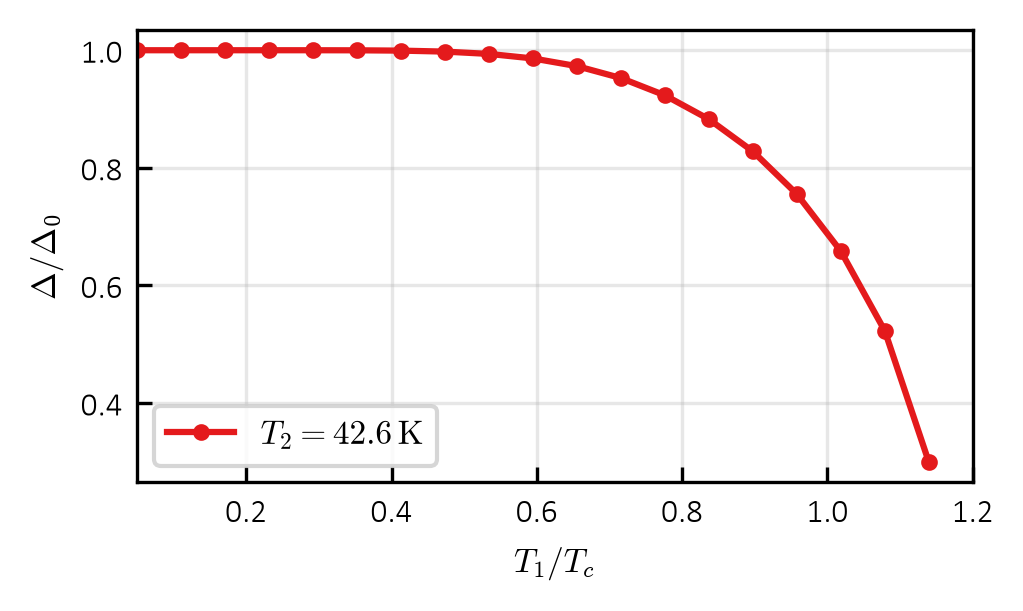

In [32]:

fig, ax = plt.subplots(figsize=(W, 0.6 * W))
ax.plot(t1r, np.array(dn)/d0, "o-", ms=3, color=set1_list[0], label=rf"$T_2 = {kel(t2):.1f}\,\mathrm{{K}}$")
ax.set_xlabel(r"$T_1/T_c$")
ax.set_ylabel(r"$\Delta/\Delta_0$")
ax.legend()
style(ax, t1r)
plt.tight_layout()
plt.show()